# Régularisation : réduction des coefficients et parcimonie

Un complément à la présentation 14

Marcel Turcotte  
2026-10-31

Ce carnet isole l’effet des pénalités L1 et L2 au carré en régression
linéaire. Les vrais coefficients des données synthétiques sont connus;
nous pouvons donc les comparer à ceux des moindres carrés ordinaires
(OLS), de Ridge et de Lasso. OLS sert de référence sans régularisation;
Ridge et Lasso appliquent respectivement L2 et L1. La présentation 14
applique les mêmes idées de pénalité aux poids des réseaux de neurones.

L’objectif est de distinguer la **réduction des coefficients**
(*shrinkage*) de la **parcimonie** (*sparsity*). Cette expérience ne
détermine pas quel estimateur prédit le mieux sur de nouvelles données.

## Données et modèles

Quinze **attributs** (*features*) sont générés, mais seuls trois ont un
vrai coefficient non nul. Avant l’ajustement, la **standardisation**
(*standardization*) donne à chaque attribut une moyenne empirique nulle
et une variance empirique unitaire. Les attributs générés ont déjà des
échelles comparables : la standardisation change donc peu les résultats
numériques ici, mais elle explicite l’hypothèse de prétraitement.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler

X, y, true_coef = make_regression(n_samples=200, n_features=15, n_informative=3,
                                 noise=10.0, coef=True, random_state=42)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Exprimer les coefficients connus dans les mêmes coordonnées que les modèles ajustés.
true_coef_scaled = true_coef * scaler.scale_
coefficient_models = {
    'OLS': LinearRegression().fit(X_scaled, y),
    'Ridge (L2)': Ridge(alpha=10.0).fit(X_scaled, y),
    'Lasso (L1)': Lasso(alpha=10.0).fit(X_scaled, y)
}

## Pourquoi standardiser?

Les unités des attributs influencent les pénalités des coefficients.
Multiplier les valeurs d’un attribut par 100 permet de diviser son
coefficient par 100 en préservant les prédictions, mais change la
pénalité de ce coefficient. La standardisation place les pénalités sur
une échelle commune entre les attributs. Elle ne crée pas elle-même la
parcimonie associée à L1. Voir la <a
href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html"
class="external" data-icon="true">documentation de StandardScaler</a>.

Pour un attribut transformé par $x'_j=(x_j-\mu_j)/s_j$, le coefficient
en coordonnées standardisées est $w'_j=s_jw_j$. Le centrage est absorbé
par l’ordonnée à l’origine ajustée. Le graphique et le tableau comparent
les **vrais coefficients et les estimations dans ces mêmes coordonnées
standardisées** : chaque coefficient décrit la variation prédite de la
cible pour une augmentation d’un écart-type de son attribut, tous les
autres attributs étant maintenus fixes.

Toutes les observations générées servent à l’entraînement dans cette
démonstration sur les coefficients. Pour évaluer les prédictions sur des
données réservées, ajuster le standardiseur uniquement sur
l’entraînement, puis l’utiliser pour transformer la validation et le
test; un pipeline scikit-learn conserve ce prétraitement avec le modèle.

## Comparer les coefficients

Les attributs informatifs et non pertinents utilisent des **échelles
verticales distinctes**. L’échelle agrandie du panneau inférieur rend
visibles les petits coefficients non nuls. Les cercles ouverts indiquent
les coefficients exactement nuls, mesurés avant l’arrondi d’affichage.

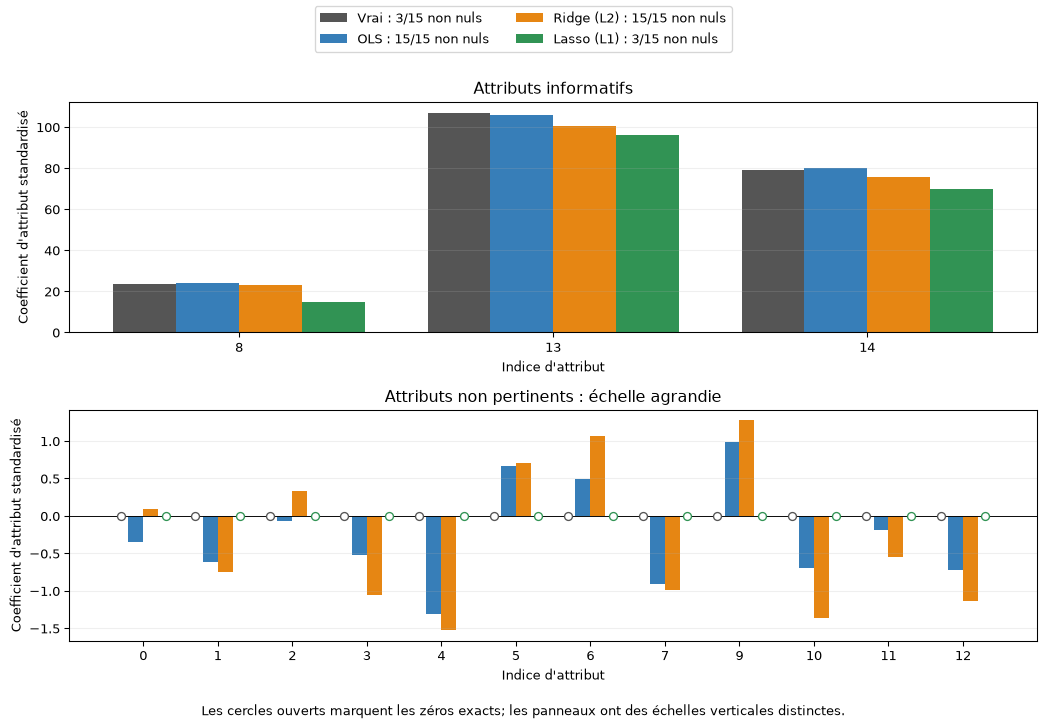

In [2]:
series = [('Vrai', true_coef_scaled)] + [
    (name, fitted.coef_) for name, fitted in coefficient_models.items()
]
colors = ['#555555', '#377eb8', '#e68613', '#319354']
groups = [
    (true_coef != 0, 'Attributs informatifs'),
    (true_coef == 0, 'Attributs non pertinents : échelle agrandie')
]
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5))
for ax, (mask, title) in zip(axes, groups):
    feature_indices = np.flatnonzero(mask)
    positions = np.arange(len(feature_indices))
    for offset, ((name, values), color) in enumerate(zip(series, colors)):
        x_positions = positions + (offset-1.5)*0.2
        nonzero = np.count_nonzero(values)
        ax.bar(x_positions, values[mask], width=0.2, color=color,
               label=f'{name} : {nonzero}/15 non nuls')
        zeros = values[mask] == 0
        ax.scatter(x_positions[zeros], values[mask][zeros], s=35,
                   facecolors='white', edgecolors=color, zorder=4)
    ax.set(xticks=positions, xticklabels=feature_indices, xlabel="Indice d'attribut",
           ylabel="Coefficient d'attribut standardisé", title=title)
    ax.axhline(0, color='black', linewidth=0.7)
    ax.grid(axis='y', alpha=0.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2)
fig.text(0.5, 0.01, 'Les cercles ouverts marquent les zéros exacts; les panneaux ont des échelles verticales distinctes.',
         ha='center')
fig.tight_layout(rect=(0, 0.035, 1, 0.91))
plt.show()

In [3]:
print(f"{'Attribut':<9} {'Vrai':>10} {'OLS':>10} {'Ridge':>10} {'Lasso':>10}")
for index, value in enumerate(true_coef_scaled):
    estimates = [fitted.coef_[index] for fitted in coefficient_models.values()]
    print(f"{index:<9} {value:>10.2f}" + ''.join(f'{estimate:>10.2f}' for estimate in estimates))

print('\nDécomptes et parcimonie, avant arrondi : ')
print(f"{'Estimateur':<12} {'Non nuls':>9} {'Nuls exacts':>14} {'Parcimonie':>11}")
for name, fitted in coefficient_models.items():
    nonzero = np.count_nonzero(fitted.coef_)
    zeros = len(fitted.coef_) - nonzero
    sparsity = 100*zeros/len(fitted.coef_)
    print(f'{name:<12} {nonzero:>9} {zeros:>14} {sparsity:>10.1f}%')
print('Vrais indices informatifs :', np.flatnonzero(true_coef))
print('Indices non nuls de Lasso : ', np.flatnonzero(coefficient_models['Lasso (L1)'].coef_))

Attribut        Vrai        OLS      Ridge      Lasso
0               0.00     -0.35      0.09      0.00
1               0.00     -0.62     -0.75     -0.00
2               0.00     -0.07      0.33      0.00
3               0.00     -0.53     -1.06     -0.00
4               0.00     -1.31     -1.52     -0.00
5               0.00      0.66      0.71      0.00
6               0.00      0.50      1.07      0.00
7               0.00     -0.91     -0.98     -0.00
8              23.71     24.13     23.25     15.02
9               0.00      0.98      1.27      0.00
10              0.00     -0.70     -1.36     -0.00
11              0.00     -0.19     -0.55     -0.00
12              0.00     -0.72     -1.13     -0.00
13            106.95    105.85    100.34     95.86
14             79.06     79.87     75.69     69.79

Décomptes et parcimonie, avant arrondi : 
Estimateur    Non nuls    Nuls exacts  Parcimonie
OLS                 15              0        0.0%
Ridge (L2)          15              0 

Avec ces réglages fixes, OLS et Ridge conservent quinze coefficients non
nuls et Lasso en conserve trois, soit 80 % de zéros exacts. Ici, Lasso
choisit les trois attributs informatifs. Cet exemple de **sélection
d’attributs** (*feature selection*) ne garantit pas la récupération des
vrais attributs dans d’autres jeux de données, notamment lorsque les
prédicteurs sont corrélés.

L2 favorise collectivement de plus petits poids et conserve généralement
une solution dense. Elle pénalise la somme des carrés des coefficients;
un coefficient individuel n’est pas nécessairement plus petit que son
estimation OLS lorsque les prédicteurs sont corrélés. Même des attributs
générés indépendamment présentent certaines corrélations dans un
échantillon fini.

L1 favorise la parcimonie : le point anguleux de la pénalité de valeur
absolue à zéro permet à l’optimum de comporter des coefficients
exactement nuls, et le solveur de Lasso par descente de coordonnées peut
trouver ces solutions parcimonieuses. Ces zéros proviennent du problème
d’optimisation. L’arrondi d’affichage ne sert pas à décider si un
coefficient est nul. Voir le <a
href="https://scikit-learn.org/stable/modules/linear_model.html#lasso"
class="external" data-icon="true">guide de Lasso</a>.

## Que signifient les coefficients de pénalité?

Les deux valeurs `alpha=10` ont été choisies pour une démonstration
qualitative. Elles ne représentent pas des pénalités de même intensité.
<a
href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html"
class="external" data-icon="true">Ridge</a> minimise

$$
\|y-Xw\|_2^2+\alpha\|w\|_2^2,
$$

tandis que <a
href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html"
class="external" data-icon="true">Lasso</a> minimise

$$
\frac{1}{2N}\|y-Xw\|_2^2+\alpha\|w\|_1.
$$

Ici, $X$ désigne la matrice des attributs standardisés et $w$ leurs
coefficients. L’ordonnée à l’origine ajustée est omise de ces
expressions compactes et n’est pas pénalisée. Les normalisations de
perte et les définitions de pénalité diffèrent; il faut donc interpréter
les coefficients de différentes API avant de les comparer.

## Lien avec les réseaux de neurones

La même idée s’applique aux entrées des matrices de poids d’un réseau.
Dans `SimpleMLP`, la fonction objectif est la BCE moyenne plus
$\lambda/2$ fois la somme des carrés des poids, et le gradient ajouté
est $\lambda W$. Les biais ne sont pas pénalisés.

L1 favorise des connexions parcimonieuses dans un réseau, mais les mises
à jour ordinaires par gradient ne donnent pas nécessairement des zéros
exacts. Un attribut d’entrée n’est entièrement déconnecté que si tous
ses poids sortants sont nuls; une connexion nulle isolée ne démontre pas
sa suppression.

## Ce que cette expérience établit

Les figures illustrent la réduction des coefficients et la parcimonie.
Les trois estimateurs conservent des nombres différents d’attributs; des
coefficients visuellement proches sur les attributs informatifs
n’établissent pas des performances prédictives égales. Un modèle plus
parcimonieux ne prédit pas automatiquement mieux.

Pour comparer les prédictions sur de nouveaux exemples, utiliser des
jeux d’entraînement, de validation et de test distincts, choisir la
pénalité de chaque estimateur avec la validation et rapporter les
erreurs finales au test. Une régularisation trop forte peut causer du
sous-apprentissage. Ici, les valeurs fixes de pénalité servent la
démonstration des coefficients et n’ont pas été choisies pour
l’exactitude prédictive.

[Retour à la présentation 14](index.qmd).